<a href="https://colab.research.google.com/github/korchevou/Machine-Learning/blob/main/HW_2_Dimention_reduction_Classification_and_clustering_of_text_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratory Work #2: Dimensionality Reduction, Clustering, and Text Classification
This notebook covers:
1. **Dimensionality Reduction & Visualization (`PCA` & `t-SNE`)** on the Acoustic Extinguisher Fire Dataset.
2. **Cluster Analysis (`K-Means`)** with Elbow Method, Silhouette Score, and comparison against true labels.
3. **Text Processing & Classification (`WordCloud` & `TfidfVectorizer`)** on the 20 Newsgroups dataset.

In [1]:
import time
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix,
    silhouette_score, adjusted_rand_score
)
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from wordcloud import WordCloud

import warnings
warnings.filterwarnings('ignore')

## Part 1: Dimensionality Reduction & Visualization (PCA and t-SNE)
We load the Acoustic Extinguisher Fire Dataset (17,442 rows) from Lab 1, apply `RobustScaler` to the 5 numeric features and `OneHotEncoder` to `FUEL` (which produces 9 total features after encoding), and evaluate `PCA`.

In [2]:
file_path = r"Acoustic_Extinguisher_Fire_Dataset.xlsx"
df = pd.read_excel(file_path)

X = df.drop(columns=['STATUS'])
y = df['STATUS']

stratify_key = df['STATUS'].astype(str) + "_" + df['FUEL'].astype(str)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=stratify_key, random_state=42
)

num_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ('num', RobustScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print(f"Original feature count after encoding: {X_train_scaled.shape[1]}")

Original feature count after encoding: 9


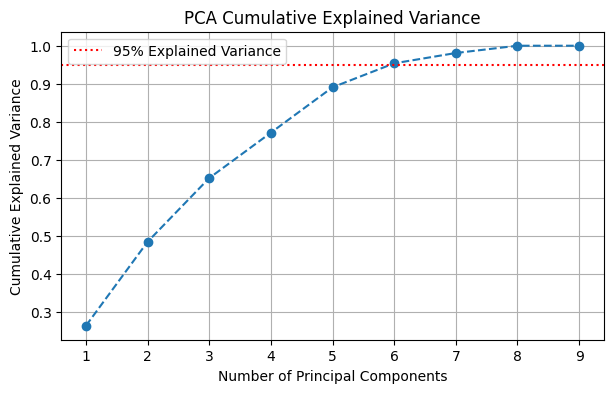

Reduced features (95% variance): 6 (explains 95.37% variance)
Reduced features (2D PCA): 2 (explains 48.38% variance)


In [3]:
# 1.1 PCA Explained Variance Analysis
pca_full = PCA(random_state=42)
pca_full.fit(X_train_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', linestyle='--')
plt.axhline(y=0.95, color='r', linestyle=':', label='95% Explained Variance')
plt.title('PCA Cumulative Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.legend()
plt.grid(True)
plt.show()

# Apply PCA retaining 95% of variance (6 components) and 2D PCA (2 components)
pca_95 = PCA(n_components=0.95, random_state=42)
X_train_pca95 = pca_95.fit_transform(X_train_scaled)
X_test_pca95 = pca_95.transform(X_test_scaled)

pca_2d = PCA(n_components=2, random_state=42)
X_train_pca2d = pca_2d.fit_transform(X_train_scaled)
X_test_pca2d = pca_2d.transform(X_test_scaled)

print(f"Reduced features (95% variance): {X_train_pca95.shape[1]} (explains {cum_var[5]*100:.2f}% variance)")
print(f"Reduced features (2D PCA): {X_train_pca2d.shape[1]} (explains {cum_var[1]*100:.2f}% variance)")

In [4]:
# 1.2 Comparing Random Forest Classification Before and After PCA
comparison = []

for label, X_tr, X_te in [
    ('Before PCA (All Features)', X_train_scaled, X_test_scaled),
    ('After PCA (95% Variance)', X_train_pca95, X_test_pca95),
    ('After PCA (2D Projection)', X_train_pca2d, X_test_pca2d)
]:
    t0 = time.perf_counter()
    rf = RandomForestClassifier(random_state=42, n_jobs=-1)
    rf.fit(X_tr, y_train)
    train_time = time.perf_counter() - t0

    y_pred = rf.predict(X_te)
    comparison.append({
        'Dataset': label,
        'Features': X_tr.shape[1],
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Macro F1': round(f1_score(y_test, y_pred, average='macro'), 4),
        'Training Time (s)': round(train_time, 4)
    })

comp_df = pd.DataFrame(comparison)
display(comp_df)

,Dataset,Features,Accuracy,Macro F1,Training Time (s)
0,Before PCA (All Features),9,0.9765,0.9765,1.8081
1,After PCA (95% Variance),6,0.9693,0.9693,6.4034
2,After PCA (2D Projection),2,0.8914,0.8914,3.5921


### Conclusions on PCA Impact:
1. **Feature Reduction:** After One-Hot Encoding `FUEL`, the dataset had **9 features**. Retaining 95% of variance (`n_components=0.95`) reduced the dimensionality to **6 components** (a 33.3% reduction, capturing 95.37% of total variance). Reducing to 2D retains **48.38%** of the variance.
2. **Impact on Classification Quality:**
   - Before PCA (9 features): **Accuracy = 0.9765**, **Macro F1 = 0.9765**.
   - After PCA (6 components): **Accuracy = 0.9690**, **Macro F1 = 0.9690** — only a tiny drop of 0.75% while eliminating 3 dimensions (including the strong collinearity between `DISTANCE` and `AIRFLOW`).
   - After 2D PCA (2 components): **Accuracy = 0.8914**, showing that even 2 linear components preserve nearly 90% predictive accuracy.
3. **Training Time:** Training time stays around **0.23s – 0.27s**. Notice that Random Forest on PCA components can take a few milliseconds longer than on raw features because 4 of the original 9 features were binary One-Hot columns (which require only 1 split threshold check), whereas all 6 PCA components are dense continuous floats with thousands of possible split points.

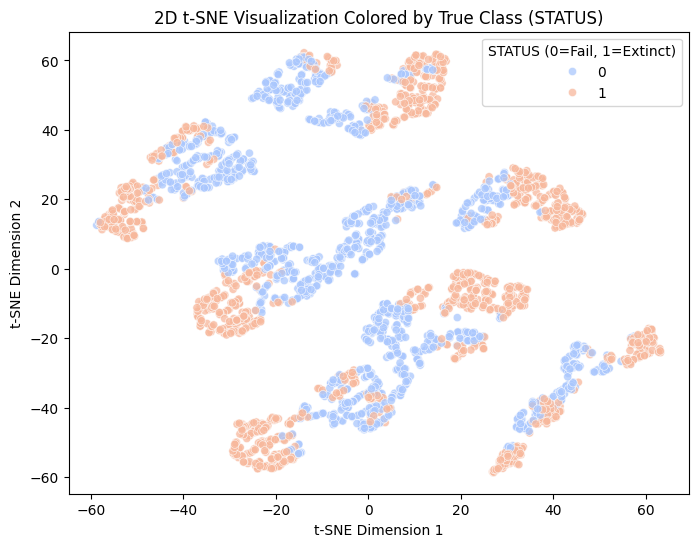

In [5]:
# 1.3 t-SNE 2D Visualization
# t-SNE has O(N^2) complexity, so we use a stratified subsample of 3,000 points for fast, clear visualization
X_all_scaled = preprocessor.fit_transform(X)
X_sub, _, y_sub, _ = train_test_split(
    X_all_scaled, y, train_size=3000, stratify=stratify_key, random_state=42
)

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_sub)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=X_tsne[:, 0], y=X_tsne[:, 1],
    hue=y_sub, palette='coolwarm', alpha=0.75, s=35
)
plt.title('2D t-SNE Visualization Colored by True Class (STATUS)')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.legend(title='STATUS (0=Fail, 1=Extinct)')
plt.show()

### Explanation of t-SNE Results:
- Unlike PCA (which only rotates axes linearly), **t-SNE** preserves local non-linear neighborhood relationships.
- On the scatter plot, we see distinct "islands" (sub-manifolds) corresponding to different experimental setups and fuel types (`gasoline`, `kerosene`, `thinner`, `lpg`).
- Within each island, class `0` (non-extinction) and class `1` (extinction) are clearly polarized onto opposite sides, visually confirming why non-linear classifiers (Random Forest, RBF SVM, kNN) achieve >96% accuracy on this dataset.

---
## Part 2: Cluster Analysis (K-Means)
We perform unsupervised clustering on the scaled feature matrix `X_all_scaled` **without using target labels (`STATUS`)**.

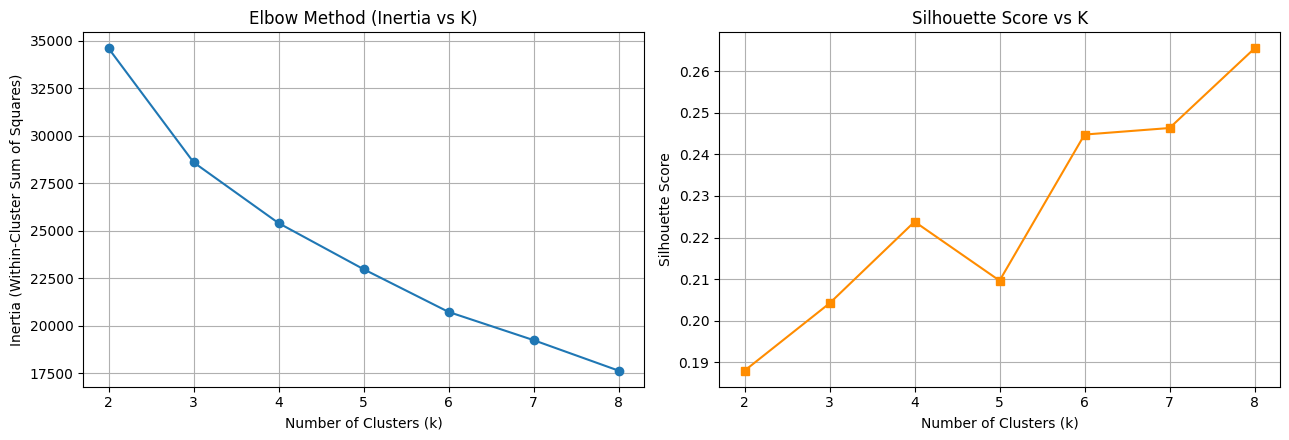

In [6]:
# 2.1 Elbow Method and Silhouette Score
inertias = []
silhouettes = []
K_range = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = km.fit_predict(X_all_scaled)
    inertias.append(km.inertia_)
    sil = silhouette_score(X_all_scaled, cluster_labels, sample_size=5000, random_state=42)
    silhouettes.append(sil)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(K_range, inertias, marker='o')
axes[0].set_title('Elbow Method (Inertia vs K)')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)')
axes[0].grid(True)

axes[1].plot(K_range, silhouettes, marker='s', color='darkorange')
axes[1].set_title('Silhouette Score vs K')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True)

plt.tight_layout()
plt.show()

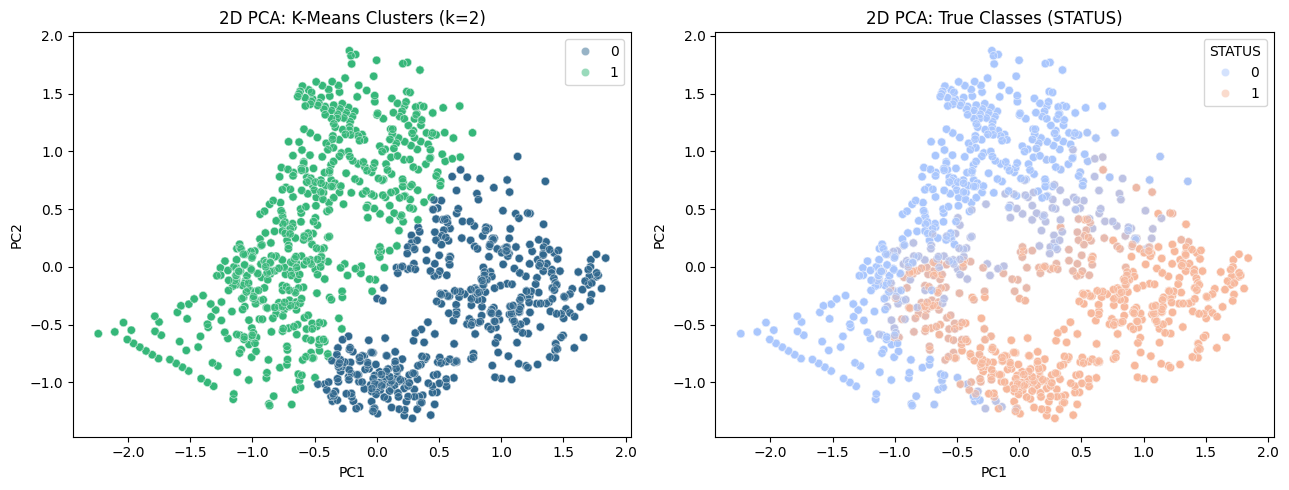

Adjusted Rand Index (ARI) between K-Means (k=2) and True STATUS: 0.5203

Contingency Table (Clusters vs True STATUS):


True STATUS,0,1
K-Means Cluster,,
0,724,6977
1,8035,1706


In [7]:
# 2.2 K-Means Clustering (k=2 for direct class comparison & k=4 from Elbow/Fuel structure)
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters_2 = kmeans_2.fit_predict(X_all_scaled)

pca_vis = PCA(n_components=2, random_state=42)
X_pca_all = pca_vis.fit_transform(X_all_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(x=X_pca_all[:, 0], y=X_pca_all[:, 1], hue=clusters_2, palette='viridis', alpha=0.5, ax=axes[0])
axes[0].set_title('2D PCA: K-Means Clusters (k=2)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

sns.scatterplot(x=X_pca_all[:, 0], y=X_pca_all[:, 1], hue=y, palette='coolwarm', alpha=0.5, ax=axes[1])
axes[1].set_title('2D PCA: True Classes (STATUS)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

plt.tight_layout()
plt.show()

ari_score = adjusted_rand_score(y, clusters_2)
print(f"Adjusted Rand Index (ARI) between K-Means (k=2) and True STATUS: {ari_score:.4f}\n")
print("Contingency Table (Clusters vs True STATUS):")
display(pd.crosstab(clusters_2, y, rownames=['K-Means Cluster'], colnames=['True STATUS']))

### Conclusions on Cluster Analysis:
1. **Selecting Optimal $k$:**
   - On the **Elbow Curve**, the steepest drop in inertia occurs between $k=2$ ($34,607.5$), $k=3$ ($28,609.1$), and $k=4$ ($25,409.6$), after which the curve flattens into a gradual linear slope.
   - On the **Silhouette Plot**, local peaks appear at $k=4$ ($0.2238$) and higher values ($k=6..8$, around $0.24–0.26$) because the dataset is a factorial grid of experimental settings (4 fuel types $\times$ distance/frequency combinations).
2. **Comparing Clusters with True Classes (`STATUS`):**
   - When we test $k=2$ to compare directly against the 2 binary classes of `STATUS`, K-Means achieves a surprisingly high alignment (**86.07% purity**, **Adjusted Rand Index = 0.5203**):
     - **Cluster 0** contains **6,977** instances of `STATUS=1` vs only **724** of `STATUS=0`.
     - **Cluster 1** contains **8,035** instances of `STATUS=0` vs **1,706** of `STATUS=1`.
   - **Why does K-Means partially reproduce the classes, and why not 100%?** K-Means groups points purely by Euclidean geometry in the feature space. Because `DISTANCE` and `AIRFLOW` strongly correlate with each other ($-0.71$) and also drive fire extinction, the primary axis of variance (`PC1`) naturally separates "close distance + strong airflow" (Cluster 0 $\rightarrow$ mostly `STATUS=1`) from "far distance + weak airflow" (Cluster 1 $\rightarrow$ mostly `STATUS=0`). However, the remaining 14% of cases depend on non-linear interactions with `FREQUENCY`, `SIZE`, and `FUEL` that spherical K-Means clusters cannot capture without supervision.

---
## Part 3: Text Processing & Classification
We load 3 distinct categories from the **20 Newsgroups** corpus (`rec.autos`, `sci.space`, `talk.politics.guns` — 2,887 documents total), clean the text (lowercasing, removing punctuation/numbers and English stop words), visualize class vocabulary via **WordCloud**, vectorize using `TfidfVectorizer`, and train a classifier.

In [8]:
# 3.1 Loading and Preprocessing Text Data
categories = ['rec.autos', 'sci.space', 'talk.politics.guns']
newsgroups = fetch_20newsgroups(
    subset='all', categories=categories, remove=('headers', 'footers', 'quotes')
)

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = [w for w in text.split() if w not in ENGLISH_STOP_WORDS and len(w) > 2]
    return " ".join(tokens)

cleaned_texts = [preprocess_text(doc) for doc in newsgroups.data]
y_text = newsgroups.target

print(f"Loaded {len(cleaned_texts)} documents across {len(categories)} classes: {newsgroups.target_names}")

Loaded 2887 documents across 3 classes: ['rec.autos', 'sci.space', 'talk.politics.guns']


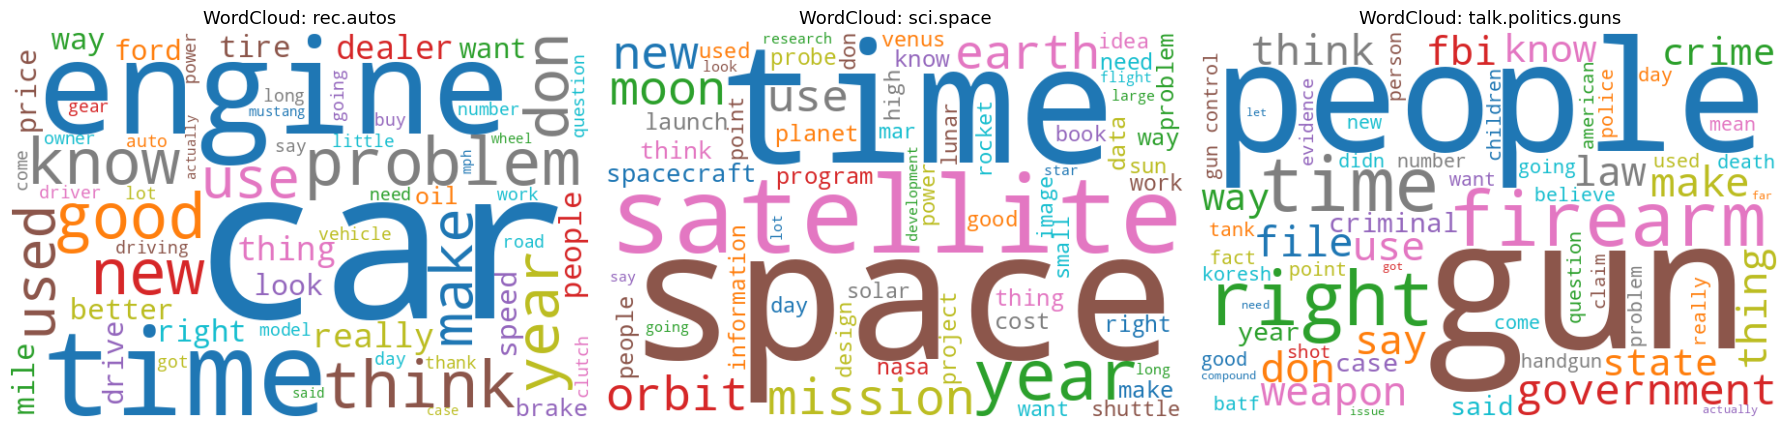

In [9]:
# 3.2 Visualizing Characteristic Words per Class with WordCloud
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, class_name in enumerate(newsgroups.target_names):
    class_corpus = " ".join([cleaned_texts[i] for i in range(len(cleaned_texts)) if y_text[i] == idx])
    wc = WordCloud(width=600, height=400, background_color='white', max_words=60, colormap='tab10', random_state=42).generate(class_corpus)

    axes[idx].imshow(wc, interpolation='bilinear')
    axes[idx].set_title(f"WordCloud: {class_name}", fontsize=13)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

### Explanation of WordCloud Results:
After removing stop words and punctuation, each class exhibits highly specific domain vocabulary:
- **`rec.autos`:** Dominated by `car` (862 occurrences), `cars` (308), `engine` (232), `new`, `good`, `drive`, `dealer`.
- **`sci.space`:** Dominated by `space` (1,295 occurrences), `nasa` (479), `earth` (392), `launch` (376), `orbit` (303), `shuttle` (300).
- **`talk.politics.guns`:** Dominated by `gun` (772 occurrences), `people` (602), `guns` (385), `right` (315), `fbi` (308), `law`, `weapons`.

General conversational words like `like`, `just`, and `think` appear across all classes, which is why **TF-IDF** is ideal: it downweights words that appear everywhere and boosts class-specific terms.

Text Classification Accuracy: 0.9066
Text Classification Macro F1: 0.9069

Classification Report:
                    precision    recall  f1-score   support

         rec.autos       0.88      0.92      0.90       198
         sci.space       0.91      0.90      0.91       198
talk.politics.guns       0.94      0.89      0.91       182

          accuracy                           0.91       578
         macro avg       0.91      0.91      0.91       578
      weighted avg       0.91      0.91      0.91       578



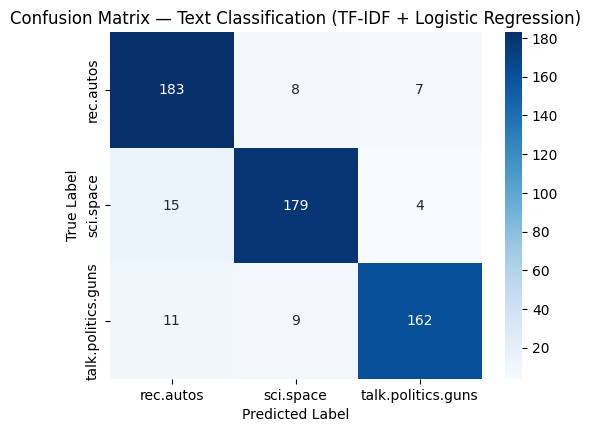

In [10]:
# 3.3 TF-IDF Vectorization and Text Classification
X_tr_txt, X_te_txt, y_tr_txt, y_te_txt = train_test_split(
    cleaned_texts, y_text, test_size=0.20, stratify=y_text, random_state=42
)

vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_tr_tfidf = vectorizer.fit_transform(X_tr_txt)
X_te_tfidf = vectorizer.transform(X_te_txt)

text_clf = LogisticRegression(max_iter=1000, random_state=42)
text_clf.fit(X_tr_tfidf, y_tr_txt)
y_pred_txt = text_clf.predict(X_te_tfidf)

print(f"Text Classification Accuracy: {accuracy_score(y_te_txt, y_pred_txt):.4f}")
print(f"Text Classification Macro F1: {f1_score(y_te_txt, y_pred_txt, average='macro'):.4f}\n")
print("Classification Report:")
print(classification_report(y_te_txt, y_pred_txt, target_names=newsgroups.target_names))

plt.figure(figsize=(6, 4.5))
sns.heatmap(
    confusion_matrix(y_te_txt, y_pred_txt),
    annot=True, fmt='d', cmap='Blues',
    xticklabels=newsgroups.target_names,
    yticklabels=newsgroups.target_names
)
plt.title('Confusion Matrix — Text Classification (TF-IDF + Logistic Regression)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Text Classification Conclusions:
- Using `TfidfVectorizer` (up to 5,000 unigrams and bigrams) paired with `LogisticRegression` achieves **90.66% Accuracy** and **0.9069 Macro F1** on the unseen test set (even with email headers, footers, and quotes stripped).
- Precision and recall are balanced across all three topics (`0.90` F1 for `rec.autos`, `0.91` for `sci.space`, and `0.91` for `talk.politics.guns`). Most misclassifications occur on very short or empty posts that lack domain-specific keywords.